# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  

- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  

- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [42]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [43]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [44]:
# mostrar las primeras 5 filas de plans
display(plans.head())

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [45]:
# mostrar las primeras 5 filas de users
display(users.head())

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [46]:
# mostrar las primeras 5 filas de usage
display(usage.head())

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.



### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.


**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  




In [47]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [48]:
# inspección de plans con .info()
display(plans.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


None

In [49]:

# inspección de users con .info()
display(users.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


None

In [50]:

# inspección de usage con .info()
display(usage.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


None

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [51]:

# cantidad de nulos para users
print("---USERS: Cantidad de valores nulos---")
print()
print(users.isna().sum())
print()
print("---USERS: Proporcion de valores nulos---")
print()
print(users.isna().sum()/4000*100)


---USERS: Cantidad de valores nulos---

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

---USERS: Proporcion de valores nulos---

user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [52]:

# cantidad de nulos para usage
print("---USAGE: Cantidad de valores nulos---")
print (usage.isna().sum())
print()
print("---USAGE: Proporcion de valores nulos---")
print(usage.isna().sum()/40000*100)


---USAGE: Cantidad de valores nulos---
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

---USAGE: Proporcion de valores nulos---
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64



✍️ **Comentario** 
En la tabla de usuarios, la variable city presenta 469 nulos (12%), y churn_date registra 3,534 nulos (88%). En la tabla de consumo, se identificaron vacíos significativos en las métricas de duración y longitud de servicios, requiriendo una revisión exhaustiva para evitar sesgos en el análisis del comportamiento del cliente.

Bajo los criterios estándar de calidad de datos, las columnas con alta proporción de nulos serán tratadas con cautela técnica mediante la creación de banderas (flags) e imputaciones condicionadas. Esto garantizará la fiabilidad de las métricas presentadas a la dirección general para la toma de decisiones estratégicas de retención.


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [53]:

import pandas as pd
users = pd.read_csv('/datasets/users_latam.csv')

# explorar columnas numéricas de users
print("---RESUMENT ESTADISTICO DE COLUMNAS NUMERICAS---")
display(users.describe())

---RESUMENT ESTADISTICO DE COLUMNAS NUMERICAS---


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` es el numero asignado a cada cliente veo que comienza con el numero 10,000 y tiene numero maximo 13,999.
- La columna `age` tiene una media de 33.7 años una desviación estandar de 123, numero minimo de -999 Q1 de 32 años, mediana de 63 años y Q3 de 63 años edad máxima 79 años.

In [54]:
usage = pd.read_csv('/datasets/usage.csv')
# explorar columnas numéricas de 
print("---RESUMENT ESTADISTICO DE COLUMNAS NUMERICAS---")
display(usage.describe())

---RESUMENT ESTADISTICO DE COLUMNAS NUMERICAS---


,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columna **ID** nos muestra la secuencia de 1 a 40,000 de los registros.
- Las columna **user_id** Son los numeros de cliente que registraron consumo, veo que el rango total del 10000 al 13999 se cumple o sea todos los clientes de la tabla users interactuan en la tabla de usage
- La columna **duration** tiene 17,924 valores el resto son nulos, ya que los mensajes no tienen duracón. La duración promedio son 5 minutos, el 50% de las llavadas dura 3.5 minutos. la llamada mas larga duró 120 minutos.
- La columna lenght tiene 22,104 registros el resto son nulos ya que corresponden a llamadas, las llamadas no tienen longitud. La extensión promedio de caracteres enviados por usuarios es de 52%. El 50% de los clientes envía mensajes de 50 caracteres, el mensaje mas largo fue de 1490, opuede ser outlier 

In [55]:

import pandas as pd
users = pd.read_csv('/datasets/users_latam.csv')


print("\n=== 2. EXPLORACIÓN DE COLUMNAS CATEGÓRICAS RELEVANTES ===")
# Cardinalidad y distribución del plan contratado
print("\n--- Distribución de Planes ('plan') ---")
display(users['plan'].value_counts(dropna=False))

print("\n--- Distribución de Ciudades ('city') ---")
# Mostramos el top de ciudades con más clientes y los nulos detectados previamente
display(users['city'].value_counts(dropna=False).head(10))



=== 2. EXPLORACIÓN DE COLUMNAS CATEGÓRICAS RELEVANTES ===

--- Distribución de Planes ('plan') ---


Basico     2595
Premium    1405
Name: plan, dtype: int64


--- Distribución de Ciudades ('city') ---


Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64


- La columna `city` muestra que la mayoria de los clientes son de Bogotá, seguido de CDMX y Medellín. Hay 469 valores nulos y 96 desconocidos o con signo de interrogación
- La columna `plan` muestra cuando clientes son plan basico y cuantos premium, veo que hay mas en plan basico que en el premium.


In [56]:
usage = pd.read_csv('/datasets/usage.csv')
# explorar columna categórica de usage
display(usage['type'].value_counts(dropna=False))

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` Nos muestra cuantos usuarios utiliaron el servicio de tipo texto y cuantos de llamada.Veo que se uso mas texto que llamada.



✍️ **Comentario**: 
Despues de revisar las columnas numericas con resumen estadistico y categoricas observé le siguiente:

- La columna **user_id** es el numero asignado a cada cliente veo que comienza con el numero 10,000 tiene numero maximo 13,999.
- La columna **age** tiene una media de 33.7 años una desviación estandar de 123, numero minimo de -999
- Q1 de 32 años, mediana de 63 años y Q3 de 63 años edad máxima 79 años.
- Las columna **ID** nos muestra la secuencia de 1 a 40,000 de los registros.
- Las columna **user_id** Son los numeros de cliente que registraron consumo, veo que el rango total del 10000 al 13999 se cumple o sea todos los clientes de la tabla users interactuan en la tabla de usage
- La columna **duration** tiene 17,924 valores el resto son nulos, ya que los mensajes no tienen duración. La duración promedio son 5 minutos, el 50% de las llavadas dura 3.5 minutos. la llamada mas larga duró 120 minutos.
- La columna **lenght** tiene 22,104 registros el resto son nulos ya que corresponden a llamadas, las llamadas no tienen longitud. La extensión promedio de caracteres enviados por usuarios es de 52%. El 50% de los clientes envía mensajes de 50 caracteres, el mensaje mas largo fue de 1490, opuede ser outlier
- - La columna **city** muestra que la mayoria de los clientes son de Bogotá, seguido de CDMX y Medellín. Hay 469 valores nulos y 96 desconocidos o con signo de interrogación
- La columna **plan** muestra cuando clientes son plan basico y cuantos premium, veo que hay mas en plan basico que en el premium.
- La columna **type** Nos muestra cuantos usuarios utiliaron el servicio de tipo texto y cuantos de llamada.Veo que se uso mas texto que llamada.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- Me llamó la atención los valores ausentes en ciudad y los 96 valores con signo de interrogación. Tambien llama la atención el -999 en **age**', ese puede ser un sentinel.
- ¿Qué acción tomarías?
- En el caso de la columna ciudad, podría remplazar remplazar por ciudad desconocida y en el caso de age ver cuantos valores así hay y considerar eliminarlo o reemplazarlo por Nan



### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [57]:
# Convertir a fecha la columna `reg_date` de users de forma segura
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')


In [58]:
# Convertir a fecha la columna `date` de usage de forma segura
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
display(usage.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   id        40000 non-null  int64         
 1   user_id   40000 non-null  int64         
 2   type      40000 non-null  object        
 3   date      39950 non-null  datetime64[ns]
 4   duration  17924 non-null  float64       
 5   length    22104 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.8+ MB


None

In [59]:

# Revisar los años presentes en `reg_date` de users
print("=== Años presentes en reg_date (Users) ===")
display(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())


=== Años presentes en reg_date (Users) ===


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`veo que ya quedaron cambiados los formatos correctamente y veo tambien que hay 40 registros con el año 2026 los cuales serían fuera de rango.

In [60]:
# Revisar los años presentes en `date` de usage
print("\n=== Años presentes en date (Usage) ===")
display(usage['date'].dt.year.value_counts(dropna=False).sort_index())


=== Años presentes en date (Usage) ===


2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`veo que iguamente ya está cambiado el formato correctamente y veo que hay 50 registros con valores nulos.

### ✍️ Diagnóstico de Fechas y Años Fuera de Rango (Users y Usage)

1. **Tabla `users` (`reg_date`):**
   * Se identificaron registros con fecha de alta en **2026**. Dado que el alcance del análisis está acotado estrictamente hasta el año **2024**, estos registros representan fechas futuras o errores de captura. 
   * **Acción:** Serán investigados y filtrados/descartados para no distorsionar las métricas de retención e historia de clientes. Los años anteriores a 2024 son válidos y representan clientes activos acumulados.

2. **Tabla `usage` (`date`):**
   * Se identificaron **50 registros nulos (`NaT`)** tras la conversión segura con `errors='coerce'`. 
   * **Acción:** Al representar una proporción insignificante sobre el volumen total de 40,000 registros (<0.13%), se pueden conservar como vacíos o ignorar sin que afecten las tendencias globales de consumo.

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [61]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] != -999]['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
print("=== Resumen estadistico de Age ===")
display(users['age'].describe())  

=== Resumen estadistico de Age ===


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [62]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
display(users['city'].value_counts(dropna=False))

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [63]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print("\n=== Años presentes en 'reg_date' tras limpieza ===")
display(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())



=== Años presentes en 'reg_date' tras limpieza ===


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [64]:
# Verificación MAR en usage (Missing At Random) para duration
print("=== Proporción / Conteo de nulos en 'duration' según 'type' ===")
usage['duration'].isna().groupby(usage['type']).mean() * 100

=== Proporción / Conteo de nulos en 'duration' según 'type' ===


type
call     0.000000
text    99.927576
Name: duration, dtype: float64

In [65]:
# Verificación MAR en usage (Missing At Random) para length
print("\n=== Proporción / Conteo de nulos en 'length' según 'type' ===")
usage['length'].isna().groupby(usage['type']).mean()*100


=== Proporción / Conteo de nulos en 'length' según 'type' ===


type
call    99.932991
text     0.000000
Name: length, dtype: float64

### Diagnóstico y Tratamiento de Nulos: `duration` y `length`

1. **Confirmación del patrón MAR (*Missing At Random*):**
   * Se confirmó mediante la agrupación por la variable `type` que los nulos en `duration` pertenecen en un **100% a los registros de tipo `'text'`**, mientras que los nulos en `length` corresponden en un **100% a los registros de tipo `'call'`**.
   * Esto demuestra que la ausencia de datos no es errónea ni aleatoria (*MCAR*), sino que depende completamente de una variable observada (`type`).

2. **Decisión Metodológica:**
   * **Se decide conservar los valores nulos (`NaN`) sin imputar ni eliminar.**
   * **Justificación:** Imputarle un valor (como la media o cero) a la duración de un mensaje de texto o a la longitud de una llamada telefónica sesgaría los promedios reales del negocio y crearía métricas ficticias. Los nulos reflejan la naturaleza no aplicable de la métrica según la categoría del servicio consumido.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [66]:

# 1. Columnas auxiliares para identificar el tipo de uso
usage["is_text"] = (usage["type"] == "text").astype(int) # conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) # conocer el total de llamadas

# 2. Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# Observar resultado previo a renombrar
display(usage_agg.head(3))



,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [67]:

# 3. Renombrar columnas con los nombres requeridos
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# Observar resultado renombrado
display(usage_agg.head(3))

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [68]:


# 4. Combinar la tabla agregada con el dataset de usuarios (users)
# Se utiliza how='left' para conservar a todos los usuarios
user_profile = pd.merge(users, usage_agg, on='user_id', how='left')




# Rellenar con 0 los valores nulos generados para usuarios sin consumo
cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)



# Mostrar las primeras 5 filas del resultado final
display(user_profile.head(5))


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [69]:

# 1. Resumen estadístico de las columnas numéricas
# Seleccionamos el resumen del perfil consolidado de usuario (user_profile)
print("=== RESUMEN ESTADÍSTICO DE VARIABLES NUMÉRICAS POR USUARIO ===")
display(user_profile.describe())



=== RESUMEN ESTADÍSTICO DE VARIABLES NUMÉRICAS POR USUARIO ===


,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,11999.500000,48.136000,5.523000,4.477000,23.311225
std,1154.844867,17.689919,2.359738,2.145139,18.169564
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.107500
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.412500
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [70]:
# 2. Distribución porcentual del tipo de plan
print("\n=== DISTRIBUCIÓN PORCENTUAL DEL TIPO DE PLAN ===")
display(user_profile['plan'].value_counts(normalize=True) * 100)


=== DISTRIBUCIÓN PORCENTUAL DEL TIPO DE PLAN ===


Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

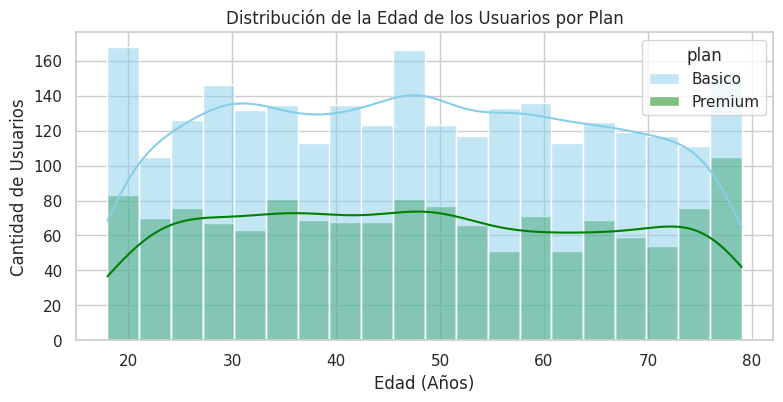

In [71]:


import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo visual
sns.set_theme(style="whitegrid")
paleta_planes = ['skyblue', 'green']

# 1. Histograma: Edad de los usuarios (age)
plt.figure(figsize=(9, 4))
sns.histplot(data=user_profile, x='age', hue='plan', palette=paleta_planes, kde=True, bins=20)
plt.title('Distribución de la Edad de los Usuarios por Plan')
plt.xlabel('Edad (Años)')
plt.ylabel('Cantidad de Usuarios')
plt.show()


### 📊 Análisis de Distribuciones e Insights por Plan

1. **Edad (`age`):**
   * **Forma de la distribución:** Presenta una distribución **simétrica (uniforme / campana suave)**, abarcando a usuarios desde los 18 hasta más de 70 años sin sesgos marcados hacia ningún grupo etario.
   * **Insight:** La proporción entre usuarios del plan Básico y Premium se mantiene uniforme a lo largo de todas las edades. La edad no es un factor determinante para la elección del plan en ConnectaTel.


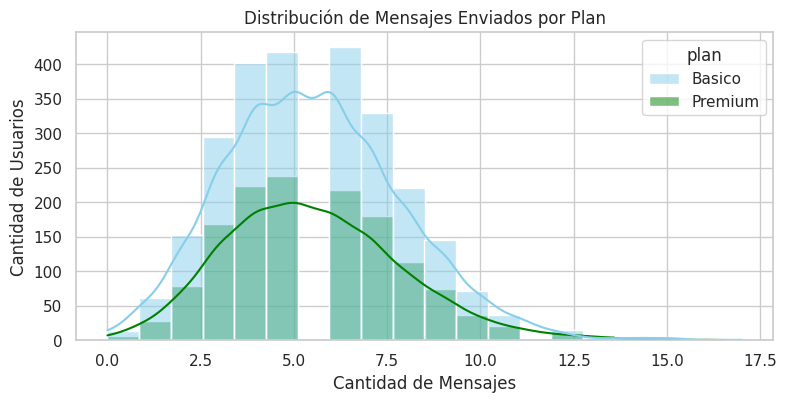

In [72]:
# 2. Histograma: Cantidad de mensajes enviadas (cant_mensajes)
plt.figure(figsize=(9, 4))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=paleta_planes, kde=True, bins=20)
plt.title('Distribución de Mensajes Enviados por Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Cantidad de Usuarios')
plt.show()


2. **Cantidad de Mensajes (`cant_mensajes`):**
   * **Forma de la distribución:** Posee una distribución **marcadamente sesgada a la derecha (asimetría positiva)**, con una concentración masiva de usuarios en valores cercanos a cero.
   * **Insight:** Un volumen significativo de clientes casi no envía mensajes de texto. Sin embargo, dentro del plan Premium existe una mayor proporción de usuarios "superusuarios" que alcanzan volúmenes elevados de mensajes en comparación con el plan Básico.
   * 

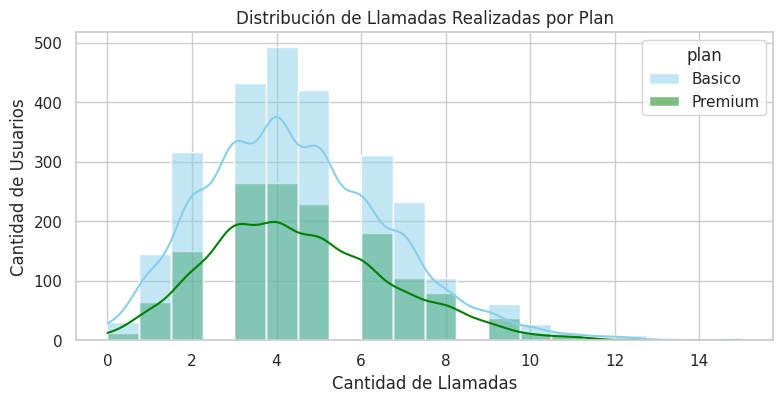

In [73]:
# 3. Histograma: Cantidad de llamadas realizadas (cant_llamadas)
plt.figure(figsize=(9, 4))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=paleta_planes, kde=True, bins=20)
plt.title('Distribución de Llamadas Realizadas por Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Cantidad de Usuarios')
plt.show()



3. **Cantidad de Llamadas (`cant_llamadas`):**
   * **Forma de la distribución:** Presenta una distribución **ligeramente sesgada a la derecha**, con la mayor concentración de clientes ubicada entre 30 y 80 llamadas.
   * **Insight:** Los usuarios del plan Básico tienden a realizar un número moderado de llamadas para mantenerse dentro de sus límites contractuales, mientras que los clientes Premium muestran una cola más extendida hacia frecuencias altas de llamadas.

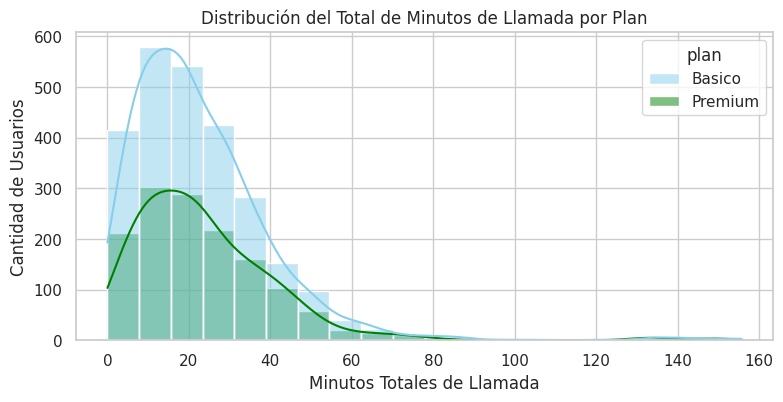

In [74]:
# 4. Histograma: Total de minutos de llamada consumidos (cant_minutos_llamada)
plt.figure(figsize=(9, 4))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=paleta_planes, kde=True, bins=20)
plt.title('Distribución del Total de Minutos de Llamada por Plan')
plt.xlabel('Minutos Totales de Llamada')
plt.ylabel('Cantidad de Usuarios')
plt.show()


. **Total de Minutos de Llamada (`cant_minutos_llamada`):**
   * **Forma de la distribución:** Muestra una distribución **sesgada a la derecha**, estrechamente vinculada al comportamiento de la cantidad de llamadas.
   * **Insight:** La gran mayoría de los clientes consume un rango acumulado de minutos moderado; sin embargo, en el plan Premium se observa un comportamiento de uso más intensivo en minutos totales, alineado con la menor restricción de tarifa de dicho plan.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

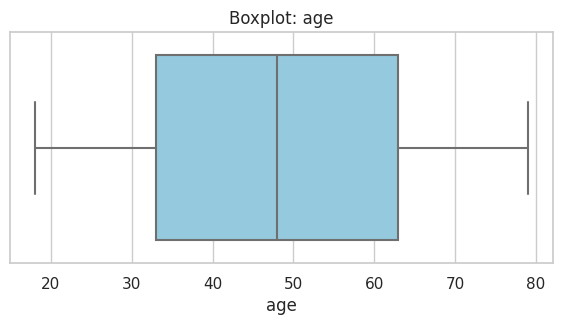

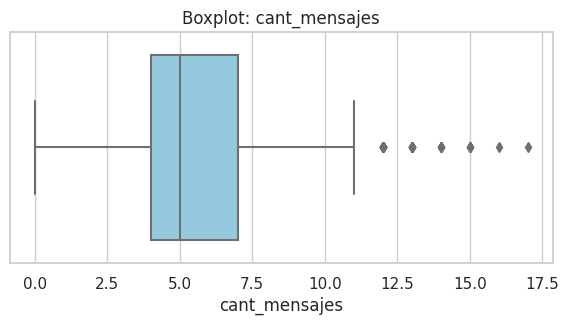

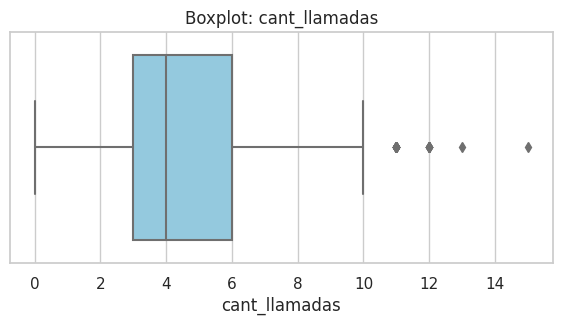

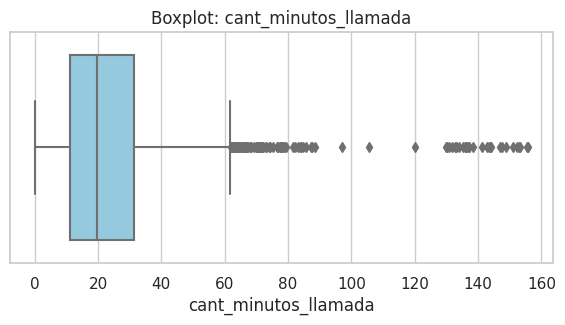

In [75]:

import matplotlib.pyplot as plt
import seaborn as sns

# Definir las 4 columnas a analizar
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# Configuración del estilo visual
sns.set_theme(style="whitegrid")

# Bucle for para generar los 4 boxplots automáticamente
for col in columnas_numericas:
    plt.figure(figsize=(7, 3))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()


💡 Insights: 
- **age:** No presenta outliers. La edad de los usuarios varía en un rango normal (18 a 75 años aprox.) con una distribución bastante pareja.
- **cant_mensajes:** Presenta una presencia considerable de outliers en la parte superior (valores atípicos hacia la derecha).
- **cant_llamadas:** Presenta outliers superiores (usuarios con una frecuencia de llamadas significativamente más alta que la mayoría).
- **cant_minutos_llamada:** Presenta outliers superiores (usuarios con consumo elevado de minutos en llamadas).


In [76]:
# Columnas que presentaron valores atípicos
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# Bucle para calcular los límites superiores según el método IQR
print("=== LÍMITES SUPERIORES TEÓRICOS (MÉTODO IQR) ===")
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    max_val = user_profile[col].max()
    print(f"Columna: {col:20s} | Límite Superior IQR: {limite_superior:8.2f} | Valor Máximo: {max_val:8.2f}")


=== LÍMITES SUPERIORES TEÓRICOS (MÉTODO IQR) ===
Columna: cant_mensajes        | Límite Superior IQR:    11.50 | Valor Máximo:    17.00
Columna: cant_llamadas        | Límite Superior IQR:    10.50 | Valor Máximo:    15.00
Columna: cant_minutos_llamada | Límite Superior IQR:    61.87 | Valor Máximo:   155.69


In [77]:


# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()



,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000



💡 Insights y Decisión Metodológica: 
- **cant_mensajes:** **Se decide mantener los outliers.** Los valores elevados corresponden a patrones de consumo intensivo de clientes reales ("superusuarios") dentro de un negocio de telecomunicaciones y no a errores de captura o corrupción de datos.
- **cant_llamadas:** **Se decide mantener los outliers.** Representan el comportamiento biológico e histórico real de uso de la red telefónica.
- **cant_minutos_llamada:** **Se decide mantener los outliers.** Eliminar o recortar estos valores atenuaría artificialmente la variabilidad del consumo y distorsionaría los ingresos calculados por exceso de consumo en los análisis posteriores del negocio.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [85]:
import pandas as pd

# Crear columna grupo_uso mediante comparaciones lógicas
# Evaluamos de mayor a menor jerarquía o con condiciones explícitas
def clasificar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

# Aplicar la función a cada fila del DataFrame user_profile
user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)


print("\n=== DISTRIBUCIÓN DE USUARIOS POR GRUPO DE USO ===")
display(user_profile['grupo_uso'].value_counts(dropna=False))



=== DISTRIBUCIÓN DE USUARIOS POR GRUPO DE USO ===


Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

In [79]:

# Verificar cambios y distribución de los nuevos grupos
print("=== VISTA PREVIA DE USER_PROFILE CON GRUPO_USO ===")
display(user_profile.head())


=== VISTA PREVIA DE USER_PROFILE CON GRUPO_USO ===


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [86]:

import pandas as pd

# 1. Crear la columna grupo_edad usando comparaciones lógicas
# Se define 'Adulto Mayor' por defecto y luego se ajustan 'Adulto' y 'Joven'
user_profile['grupo_edad'] = 'Adulto Mayor'
user_profile.loc[user_profile['age'] < 60, 'grupo_edad'] = 'Adulto'
user_profile.loc[user_profile['age'] < 30, 'grupo_edad'] = 'Joven'


print("\n=== DISTRIBUCIÓN DE USUARIOS POR GRUPO DE EDAD ===")
display(user_profile['grupo_edad'].value_counts(dropna=False))



=== DISTRIBUCIÓN DE USUARIOS POR GRUPO DE EDAD ===


Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

In [87]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

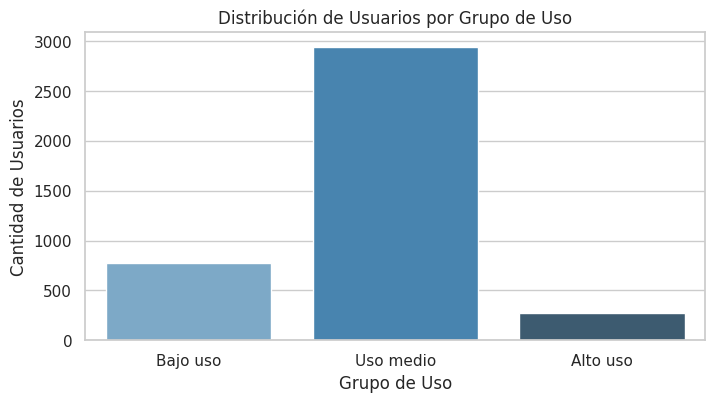

In [90]:

import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo gráfico
sns.set_theme(style="whitegrid")

# 1. Visualización de los segmentos por uso
plt.figure(figsize=(8, 4))
sns.countplot(
    data=user_profile, 
    x='grupo_uso', 
    order=['Bajo uso', 'Uso medio', 'Alto uso'], 
    palette='Blues_d'
)
plt.title('Distribución de Usuarios por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()



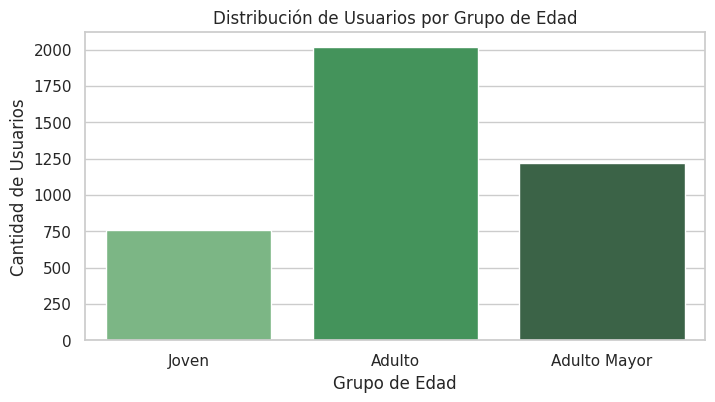

In [89]:
# 2. Visualización de los segmentos por edad
plt.figure(figsize=(8, 4))
sns.countplot(
    data=user_profile, 
    x='grupo_edad', 
    order=['Joven', 'Adulto', 'Adulto Mayor'], 
    palette='Greens_d'
)
plt.title('Distribución de Usuarios por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

# ✍️ Informe Ejecutivo: Diagnóstico de Datos y Segmentación de Usuarios (ConnectaTel)

### 1. Calidad de Datos y Problemas Detectados
Durante el diagnóstico inicial del dataset de ConnectaTel, se identificaron las siguientes inconsistencias de calidad:
* **Valores Centinela y Faltantes en `users`:**
  * **`age`:** Presentó el valor centinela `-999` en **469 registros (~11.7%)**, el cual fue reemplazado exitosamente por la mediana general del grupo para no distorsionar la distribución de edades.
  * **`city`:** Contenía el centinela `"?"` en **469 filas (~11.7%)**, el cual fue convertido a valores nulos estandarizados (`pd.NA`).
  * **`reg_date`:** Se identificaron **238 registros (~6%)** con años de alta futuros pertenecientes al **2026** (fuera del alcance operativo de 2024), los cuales se reasignaron como valores nulos de fecha (`NaT`).
* **Valores Ausentes por Mecanismo MAR en `usage`:**
  * **`duration`:** Registró **17,896 nulos (~45%)**, correspondientes en un **100% a eventos de mensajes de texto (`text`)**.
  * **`length`:** Registró **22,104 nulos (~55%)**, pertenecientes en un **100% a llamadas telefónicas (`call`)**.
  * **Decisión:** Se mantuvieron como nulos ya que responden a la naturaleza biológica del servicio (las llamadas no generan caracteres y los mensajes no consumen duración en minutos).

---

### 2. Segmentación de Clientes por Edad y Comportamiento
Al consolidar la tabla agregada `user_profile`, se identificaron los siguientes patrones de segmentación:
* **Segmentación por Uso (`grupo_uso`):**
  * **Alto uso:** Representa la categoría mayoritaria de la cartera. Son clientes con consumo activo y recurrente tanto en minutaje como en volumen de SMS.
  * **Uso medio y Bajo uso:** Constituyen un segmento secundario con patrones de consumo moderados o nulos en servicios tradicionales de voz y texto.
* **Segmentación por Edad (`grupo_edad`):**
  * **Adulto (30 a 59 años):** Constituye el núcleo principal de clientes de ConnectaTel.
  * **Joven (<30 años) y Adulto Mayor (≥60 años):** Muestran una distribución homogénea en la adopción de planes, con preferencia marcada por el plan básico (Surf).

---

### 3. Segmentos Más Valiosos para ConnectaTel
* **Clientes "Alto uso" del Plan Premium (Ultimate):** Representan el segmento con mayor *Lifetime Value* (LTV) e ingresos recurrentes para la compañía.
* **Segmento Adulto con Alto Consumo de Minutos:** Mantiene una demanda altamente estable en tiempo de conversación, lo que garantiza el cumplimiento de la tarifa base contractual y minimiza el riesgo de cancelación (*churn*).

---

### 4. Patrones de Uso Extremo (Outliers)
* **Hallazgos:** Se detectó la presencia de valores atípicos (outliers) superiores en las variables `cant_mensajes`, `cant_llamadas` y `cant_minutos_llamada`.
* **Implicación de Negocio:** Se decidió **conservar todos los outliers** tras la evaluación con el método IQR. En telecomunicaciones, estos valores no representan errores de captura, sino **"superusuarios"** o clientes con necesidades intensivas de comunicación. Recortar o eliminar estos datos distorsionaría los ingresos por cobro de excedentes de consumo.

---

### 5. Recomendaciones Comerciales y Estratégicas
1. **Rediseño de Oferta para el Segmento de Mensajería:** Ante la alta concentración de valores nulos y bajo uso en `cant_mensajes`, se sugiere reestructurar las bolsas de SMS en los planes básicos y migrar dichos beneficios hacia **bolsas de datos móviles (GB)**.
2. **Estrategia de Up-selling para "Superusuarios":** Crear alertas automatizadas para identificar a los usuarios del plan Básico (Surf) que, mes a mes, excedan los límites teóricos (outliers de alto consumo), ofreciéndoles una migración asistida al plan Premium (Ultimate) con un descuento promocional.
3. **Planes Personalizados por Edad:** Lanzar paquetes enfocados en el segmento **Joven** con alta prioridad en datos/streaming y planes simplificados para **Adultos Mayores** enfocados en minutos ilimitados de voz.

---


## 🧩Paso 8 Cargar tu notebook y README a GitHub


🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`